In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [1]:
!wget -O synthea.zip https://synthetichealth.github.io/synthea-sample-data/downloads/synthea_sample_data_csv_apr2020.zip

--2026-11-11 15:04:31--  https://synthetichealth.github.io/synthea-sample-data/downloads/synthea_sample_data_csv_apr2020.zip
Resolving synthetichealth.github.io (synthetichealth.github.io)... 185.199.108.153, 185.199.109.153, 185.199.110.153, ...
Connecting to synthetichealth.github.io (synthetichealth.github.io)|185.199.108.153|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 8982431 (8.6M) [application/x-zip-compressed]
Saving to: ‘synthea.zip’

synthea.zip         100%[===================>]   8.57M  32.9MB/s    in 0.3s    

2026-11-11 15:04:32 (32.9 MB/s) - ‘synthea.zip’ saved [8982431/8982431]



In [2]:
!unzip -o synthea.zip -d /content/synthea_data

Archive:  synthea.zip
   creating: /content/synthea_data/csv/
  inflating: /content/synthea_data/csv/medications.csv  
  inflating: /content/synthea_data/csv/providers.csv  
  inflating: /content/synthea_data/csv/payer_transitions.csv  
  inflating: /content/synthea_data/csv/imaging_studies.csv  
  inflating: /content/synthea_data/csv/supplies.csv  
  inflating: /content/synthea_data/csv/payers.csv  
  inflating: /content/synthea_data/csv/allergies.csv  
  inflating: /content/synthea_data/csv/procedures.csv  
  inflating: /content/synthea_data/csv/organizations.csv  
  inflating: /content/synthea_data/csv/conditions.csv  
  inflating: /content/synthea_data/csv/careplans.csv  
  inflating: /content/synthea_data/csv/encounters.csv  
  inflating: /content/synthea_data/csv/devices.csv  
  inflating: /content/synthea_data/csv/immunizations.csv  
  inflating: /content/synthea_data/csv/patients.csv  
  inflating: /content/synthea_data/csv/observations.csv  


In [3]:
import os

path = "/content/synthea_data"

for file in os.listdir(path):
    print(file)

csv


In [4]:
import glob
import os

files = glob.glob(
    "/content/synthea_data/**/*.csv",
    recursive=True
)

print("Total CSV files:", len(files))

for file in files:
    print(os.path.basename(file))

Total CSV files: 16
devices.csv
allergies.csv
immunizations.csv
organizations.csv
payers.csv
payer_transitions.csv
providers.csv
patients.csv
imaging_studies.csv
conditions.csv
encounters.csv
procedures.csv
medications.csv
observations.csv
careplans.csv
supplies.csv


In [6]:
import os

path = "/content/synthea_data/csv"

files = os.listdir(path)

print("Total files:", len(files))

for file in files:
    print(file)

Total files: 16
devices.csv
allergies.csv
immunizations.csv
organizations.csv
payers.csv
payer_transitions.csv
providers.csv
patients.csv
imaging_studies.csv
conditions.csv
encounters.csv
procedures.csv
medications.csv
observations.csv
careplans.csv
supplies.csv


In [7]:
import os

path = "/content/synthea_data/csv"

files = os.listdir(path)

print("Total files:", len(files))

for file in files:
    print(file)

Total files: 16
devices.csv
allergies.csv
immunizations.csv
organizations.csv
payers.csv
payer_transitions.csv
providers.csv
patients.csv
imaging_studies.csv
conditions.csv
encounters.csv
procedures.csv
medications.csv
observations.csv
careplans.csv
supplies.csv


In [8]:
import pandas as pd

patients = pd.read_csv(path + "/patients.csv")
encounters = pd.read_csv(path + "/encounters.csv")

print("Patients:", patients.shape)
print("Encounters:", encounters.shape)

display(patients.head())
display(encounters.head())

Patients: (1171, 25)
Encounters: (53346, 15)


,Id,BIRTHDATE,DEATHDATE,SSN,DRIVERS,PASSPORT,PREFIX,FIRST,LAST,SUFFIX,...,BIRTHPLACE,ADDRESS,CITY,STATE,COUNTY,ZIP,LAT,LON,HEALTHCARE_EXPENSES,HEALTHCARE_COVERAGE
0,1d604da9-9a81-4ba9-80c2-de3375d59b40,1989-05-25,NaN,999-76-6866,S99984236,X19277260X,Mr.,José Eduardo181,Gómez206,NaN,...,Marigot Saint Andrew Parish DM,427 Balistreri Way Unit 19,Chicopee,Massachusetts,Hampden County,1013.0,42.228354,-72.562951,271227.08,1334.88
1,034e9e3b-2def-4559-bb2a-7850888ae060,1983-11-14,NaN,999-73-5361,S99962402,X88275464X,Mr.,Milo271,Feil794,NaN,...,Danvers Massachusetts US,422 Farrell Path Unit 69,Somerville,Massachusetts,Middlesex County,2143.0,42.360697,-71.126531,793946.01,3204.49
2,10339b10-3cd1-4ac3-ac13-ec26728cb592,1992-06-02,NaN,999-27-3385,S99972682,X73754411X,Mr.,Jayson808,Fadel536,NaN,...,Springfield Massachusetts US,1056 Harris Lane Suite 70,Chicopee,Massachusetts,Hampden County,1020.0,42.181642,-72.608842,574111.90,2606.40
3,8d4c4326-e9de-4f45-9a4c-f8c36bff89ae,1978-05-27,NaN,999-85-4926,S99974448,X40915583X,Mrs.,Mariana775,Rutherford999,NaN,...,Yarmouth Massachusetts US,999 Kuhn Forge,Lowell,Massachusetts,Middlesex County,1851.0,42.636143,-71.343255,935630.30,8756.19
4,f5dcd418-09fe-4a2f-baa0-3da800bd8c3a,1996-10-18,NaN,999-60-7372,S99915787,X86772962X,Mr.,Gregorio366,Auer97,NaN,...,Patras Achaea GR,1050 Lindgren Extension Apt 38,Boston,Massachusetts,Suffolk County,2135.0,42.352434,-71.028610,598763.07,3772.20


,Id,START,STOP,PATIENT,ORGANIZATION,PROVIDER,PAYER,ENCOUNTERCLASS,CODE,DESCRIPTION,BASE_ENCOUNTER_COST,TOTAL_CLAIM_COST,PAYER_COVERAGE,REASONCODE,REASONDESCRIPTION
0,d0c40d10-8d87-447e-836e-99d26ad52ea5,2010-01-23T17:45:28Z,2010-01-23T18:10:28Z,034e9e3b-2def-4559-bb2a-7850888ae060,e002090d-4e92-300e-b41e-7d1f21dee4c6,e6283e46-fd81-3611-9459-0edb1c3da357,6e2f1a2d-27bd-3701-8d08-dae202c58632,ambulatory,185345009,Encounter for symptom,129.16,129.16,54.16,10509002.0,Acute bronchitis (disorder)
1,e88bc3a9-007c-405e-aabc-792a38f4aa2b,2012-01-23T17:45:28Z,2012-01-23T18:00:28Z,034e9e3b-2def-4559-bb2a-7850888ae060,772ee193-bb9f-30eb-9939-21e86c8e4da5,6f1d59a7-a5bd-3cf9-9671-5bad2f351c28,6e2f1a2d-27bd-3701-8d08-dae202c58632,wellness,162673000,General examination of patient (procedure),129.16,129.16,129.16,NaN,NaN
2,8f104aa7-4ca9-4473-885a-bba2437df588,2001-05-01T15:02:18Z,2001-05-01T15:17:18Z,1d604da9-9a81-4ba9-80c2-de3375d59b40,5d4b9df1-93ae-3bc9-b680-03249990e558,af01a385-31d3-3c77-8fdb-2867fe88df2f,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,ambulatory,185345009,Encounter for symptom,129.16,129.16,0.00,36971009.0,Sinusitis (disorder)
3,b85c339a-6076-43ed-b9d0-9cf013dec49d,2011-07-28T15:02:18Z,2011-07-28T15:17:18Z,1d604da9-9a81-4ba9-80c2-de3375d59b40,3dc9bb2d-5d66-3e61-bf9a-e234c6433577,bb17e691-262b-3546-93d5-d88e7de93246,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,wellness,162673000,General examination of patient (procedure),129.16,129.16,0.00,NaN,NaN
4,dae2b7cb-1316-4b78-954f-fa610a6c6d0e,2010-07-27T12:58:08Z,2010-07-27T13:28:08Z,10339b10-3cd1-4ac3-ac13-ec26728cb592,b03dba4f-892f-365c-bfd1-bfcfa7a98d5d,7ed6b84a-b847-3744-9d42-15c42297a0c2,d47b3510-2895-3b70-9897-342d681c769d,wellness,162673000,General examination of patient (procedure),129.16,129.16,129.16,NaN,NaN


In [9]:
import pandas as pd
import os
import glob

path = "/content/synthea_data/csv"

csv_files = glob.glob(path + "/*.csv")

dataset_summary = []

for file in csv_files:
    df = pd.read_csv(file)

    dataset_summary.append({
        "Table": os.path.basename(file),
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Values": df.isnull().sum().sum()
    })

summary = pd.DataFrame(dataset_summary)

display(summary)

,Table,Rows,Columns,Missing Values
0,devices.csv,78,7,78
1,allergies.csv,597,6,533
2,immunizations.csv,15478,6,0
3,organizations.csv,1119,11,184
4,payers.csv,10,21,5
5,payer_transitions.csv,3801,5,236
6,providers.csv,5855,12,0
7,patients.csv,1171,25,4652
8,imaging_studies.csv,855,10,0
9,conditions.csv,8376,6,3811


In [10]:
for file in csv_files:
    df = pd.read_csv(file, nrows=5)

    print("\nTABLE:", os.path.basename(file))
    print(df.columns.tolist())


TABLE: devices.csv
['START', 'STOP', 'PATIENT', 'ENCOUNTER', 'CODE', 'DESCRIPTION', 'UDI']

TABLE: allergies.csv
['START', 'STOP', 'PATIENT', 'ENCOUNTER', 'CODE', 'DESCRIPTION']

TABLE: immunizations.csv
['DATE', 'PATIENT', 'ENCOUNTER', 'CODE', 'DESCRIPTION', 'BASE_COST']

TABLE: organizations.csv
['Id', 'NAME', 'ADDRESS', 'CITY', 'STATE', 'ZIP', 'LAT', 'LON', 'PHONE', 'REVENUE', 'UTILIZATION']

TABLE: payers.csv
['Id', 'NAME', 'ADDRESS', 'CITY', 'STATE_HEADQUARTERED', 'ZIP', 'PHONE', 'AMOUNT_COVERED', 'AMOUNT_UNCOVERED', 'REVENUE', 'COVERED_ENCOUNTERS', 'UNCOVERED_ENCOUNTERS', 'COVERED_MEDICATIONS', 'UNCOVERED_MEDICATIONS', 'COVERED_PROCEDURES', 'UNCOVERED_PROCEDURES', 'COVERED_IMMUNIZATIONS', 'UNCOVERED_IMMUNIZATIONS', 'UNIQUE_CUSTOMERS', 'QOLS_AVG', 'MEMBER_MONTHS']

TABLE: payer_transitions.csv
['PATIENT', 'START_YEAR', 'END_YEAR', 'PAYER', 'OWNERSHIP']

TABLE: providers.csv
['Id', 'ORGANIZATION', 'NAME', 'GENDER', 'SPECIALITY', 'ADDRESS', 'CITY', 'STATE', 'ZIP', 'LAT', 'LON', 'UT

In [11]:
import pandas as pd
import os

path = "/content/synthea_data/csv"

# Load essential datasets
patients = pd.read_csv(path + "/patients.csv")
encounters = pd.read_csv(path + "/encounters.csv")
conditions = pd.read_csv(path + "/conditions.csv")

# Display complete column names
print("PATIENT COLUMNS")
print(patients.columns.tolist())

print("\nENCOUNTER COLUMNS")
print(encounters.columns.tolist())

print("\nCONDITION COLUMNS")
print(conditions.columns.tolist())

PATIENT COLUMNS
['Id', 'BIRTHDATE', 'DEATHDATE', 'SSN', 'DRIVERS', 'PASSPORT', 'PREFIX', 'FIRST', 'LAST', 'SUFFIX', 'MAIDEN', 'MARITAL', 'RACE', 'ETHNICITY', 'GENDER', 'BIRTHPLACE', 'ADDRESS', 'CITY', 'STATE', 'COUNTY', 'ZIP', 'LAT', 'LON', 'HEALTHCARE_EXPENSES', 'HEALTHCARE_COVERAGE']

ENCOUNTER COLUMNS
['Id', 'START', 'STOP', 'PATIENT', 'ORGANIZATION', 'PROVIDER', 'PAYER', 'ENCOUNTERCLASS', 'CODE', 'DESCRIPTION', 'BASE_ENCOUNTER_COST', 'TOTAL_CLAIM_COST', 'PAYER_COVERAGE', 'REASONCODE', 'REASONDESCRIPTION']

CONDITION COLUMNS
['START', 'STOP', 'PATIENT', 'ENCOUNTER', 'CODE', 'DESCRIPTION']


In [12]:
# Check missing values and data types

for name, df in {
    "Patients": patients,
    "Encounters": encounters,
    "Conditions": conditions
}.items():

    print("\n==========", name, "==========")

    print("Shape:", df.shape)

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:", df.duplicated().sum())


========== Patients ==========
Shape: (1171, 25)

Data types:
Id                      object
BIRTHDATE               object
DEATHDATE               object
SSN                     object
DRIVERS                 object
PASSPORT                object
PREFIX                  object
FIRST                   object
LAST                    object
SUFFIX                  object
MAIDEN                  object
MARITAL                 object
RACE                    object
ETHNICITY               object
GENDER                  object
BIRTHPLACE              object
ADDRESS                 object
CITY                    object
STATE                   object
COUNTY                  object
ZIP                    float64
LAT                    float64
LON                    float64
HEALTHCARE_EXPENSES    float64
HEALTHCARE_COVERAGE    float64
dtype: object

Missing values:
Id                        0
BIRTHDATE                 0
DEATHDATE              1000
SSN                       0
DRIVERS            

In [13]:
print("Unique patients in patients table:",
      patients["Id"].nunique())

print("Unique patients in encounters:",
      encounters["PATIENT"].nunique())

print("\nEncounter classes:")
print(encounters["ENCOUNTERCLASS"].value_counts())

print("\nUnique healthcare organizations:",
      encounters["ORGANIZATION"].nunique())

print("\nEncounter date range:")
print("Start:", encounters["START"].min())
print("End:", encounters["START"].max())

Unique patients in patients table: 1171
Unique patients in encounters: 1171

Encounter classes:
ENCOUNTERCLASS
wellness      19106
ambulatory    18936
outpatient     9003
urgentcare     2373
emergency      2090
inpatient      1838
Name: count, dtype: int64

Unique healthcare organizations: 1103

Encounter date range:
Start: 1912-07-21T19:05:21Z
End: 2020-04-28T18:58:37Z


In [14]:
# Convert dates into datetime format

encounters['START'] = pd.to_datetime(
    encounters['START'],
    errors='coerce',
    utc=True
)

encounters['STOP'] = pd.to_datetime(
    encounters['STOP'],
    errors='coerce',
    utc=True
)

# Check date distribution

print("Date statistics:")
print(encounters['START'].describe())

print("\nEarliest 10 encounters:")
print(encounters['START'].nsmallest(10))

print("\nLatest 10 encounters:")
print(encounters['START'].nlargest(10))

Date statistics:
count                                  53346
mean     2004-03-01 20:12:15.798935296+00:00
min                1912-07-21 19:05:21+00:00
25%         1997-02-27 09:39:10.250000+00:00
50%                2011-08-08 08:50:18+00:00
75%      2015-12-24 03:14:24.249999872+00:00
max                2020-04-28 18:58:37+00:00
Name: START, dtype: object

Earliest 10 encounters:
33689   1912-07-21 19:05:21+00:00
33690   1912-07-29 19:05:21+00:00
26842   1913-06-17 04:54:18+00:00
48158   1915-08-02 09:30:42+00:00
48159   1915-08-19 09:30:42+00:00
52361   1915-09-04 17:27:52+00:00
52362   1915-09-12 17:27:52+00:00
17450   1916-05-05 23:35:03+00:00
17451   1916-11-03 23:35:03+00:00
23021   1916-12-28 09:59:52+00:00
Name: START, dtype: datetime64[ns, UTC]

Latest 10 encounters:
357     2020-04-28 18:58:37+00:00
944     2020-04-28 10:13:45+00:00
4591    2020-04-27 23:46:02+00:00
26381   2020-04-27 19:30:37+00:00
28162   2020-04-27 18:42:35+00:00
51716   2020-04-26 22:57:51+00:00
3569    2

In [15]:
print("Top 10 organisations by encounter count:")

display(
    encounters['ORGANIZATION']
    .value_counts()
    .head(10)
)

Top 10 organisations by encounter count:


,count
ORGANIZATION,
be4c63f3-8d38-3fa9-a183-62045b5c85f6,3217
d311e70d-86e7-3c03-b115-53892bcf7ef1,1972
d692e283-0833-3201-8e55-4f868a9c0736,1658
e002090d-4e92-300e-b41e-7d1f21dee4c6,1028
3d10019f-c88e-3de5-9916-6107b9c0263d,955
3bd5eda0-16da-3ba5-8500-4dfd6ae118b8,859
465de31f-3098-365c-af70-48a071e1f5aa,857
24cb4eab-6166-3530-bddc-a5a8a14a4fc1,824
5d4b9df1-93ae-3bc9-b680-03249990e558,783


Encounters by year:


,count
YEAR,
1912,2
1913,1
1915,4
1916,3
1917,3
...,...
2016,3148
2017,3153
2018,3090


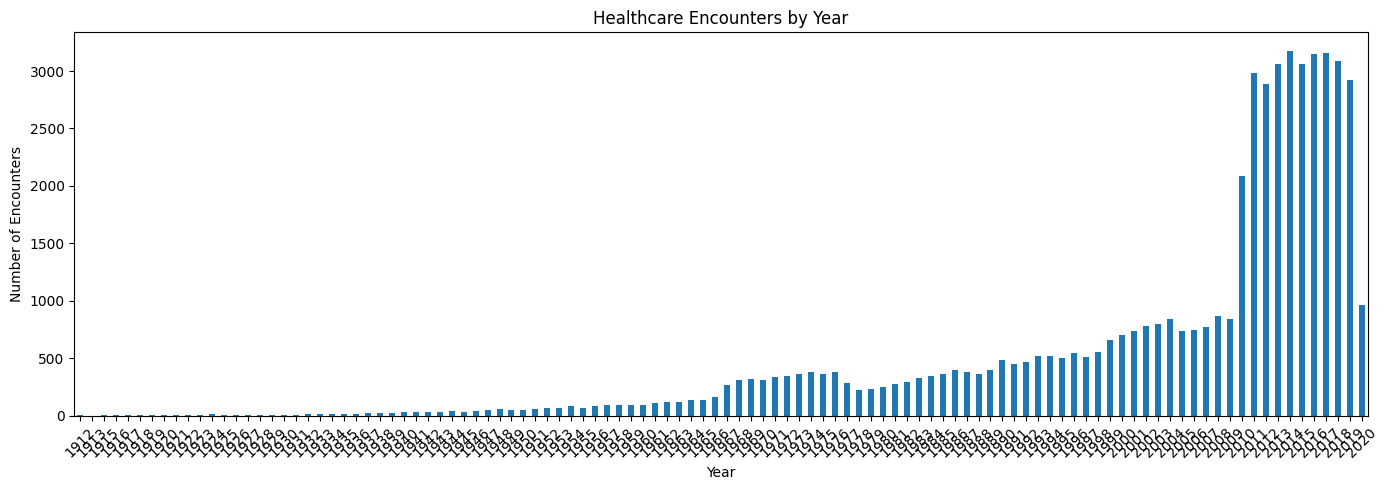

In [16]:
# Extract year from encounter date

encounters['YEAR'] = encounters['START'].dt.year

yearly_data = encounters['YEAR'].value_counts().sort_index()

print("Encounters by year:")
display(yearly_data)

# Visualise yearly distribution

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
yearly_data.plot(kind='bar')

plt.title("Healthcare Encounters by Year")
plt.xlabel("Year")
plt.ylabel("Number of Encounters")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [17]:
organizations = pd.read_csv(path + "/organizations.csv")

# Merge encounter counts with organisation details

org_counts = (
    encounters.groupby('ORGANIZATION')
    .size()
    .reset_index(name='ENCOUNTER_COUNT')
)

org_analysis = org_counts.merge(
    organizations[['Id', 'NAME', 'CITY', 'STATE']],
    left_on='ORGANIZATION',
    right_on='Id',
    how='left'
)

# Display top 15 organisations

display(
    org_analysis.sort_values(
        'ENCOUNTER_COUNT',
        ascending=False
    ).head(15)
)

,ORGANIZATION,ENCOUNTER_COUNT,Id,NAME,CITY,STATE
805,be4c63f3-8d38-3fa9-a183-62045b5c85f6,3217,be4c63f3-8d38-3fa9-a183-62045b5c85f6,VA Boston Healthcare System Jamaica Plain Campus,Jamaica Plain,MA
887,d311e70d-86e7-3c03-b115-53892bcf7ef1,1972,d311e70d-86e7-3c03-b115-53892bcf7ef1,Worcester Outpatient Clinic,Worcester,MA
904,d692e283-0833-3201-8e55-4f868a9c0736,1658,d692e283-0833-3201-8e55-4f868a9c0736,HALLMARK HEALTH SYSTEM,MELROSE,MA
946,e002090d-4e92-300e-b41e-7d1f21dee4c6,1028,e002090d-4e92-300e-b41e-7d1f21dee4c6,CAMBRIDGE HEALTH ALLIANCE,CAMBRIDGE,MA
246,3d10019f-c88e-3de5-9916-6107b9c0263d,955,3d10019f-c88e-3de5-9916-6107b9c0263d,NEWTON-WELLESLEY HOSPITAL,NEWTON,MA
238,3bd5eda0-16da-3ba5-8500-4dfd6ae118b8,859,3bd5eda0-16da-3ba5-8500-4dfd6ae118b8,NORWOOD HOSPITAL,NORWOOD,MA
297,465de31f-3098-365c-af70-48a071e1f5aa,857,465de31f-3098-365c-af70-48a071e1f5aa,METROWEST MEDICAL CENTER,FRAMINGHAM,MA
147,24cb4eab-6166-3530-bddc-a5a8a14a4fc1,824,24cb4eab-6166-3530-bddc-a5a8a14a4fc1,MILFORD REGIONAL MEDICAL CENTER,MILFORD,MA
389,5d4b9df1-93ae-3bc9-b680-03249990e558,783,5d4b9df1-93ae-3bc9-b680-03249990e558,HOLYOKE MEDICAL CENTER,HOLYOKE,MA
393,5e765f2b-e908-3888-9fc7-df2cb87beb58,763,5e765f2b-e908-3888-9fc7-df2cb87beb58,STURDY MEMORIAL HOSPITAL,ATTLEBORO,MA


In [18]:
yearly_summary = (
    encounters.groupby('YEAR')
    .agg(
        Total_Encounters=('Id', 'count'),
        Unique_Patients=('PATIENT', 'nunique')
    )
    .reset_index()
)

display(yearly_summary.tail(15))

,YEAR,Total_Encounters,Unique_Patients
93,2006,750,354
94,2007,775,355
95,2008,865,376
96,2009,841,436
97,2010,2083,800
98,2011,2979,897
99,2012,2890,883
100,2013,3058,906
101,2014,3178,901
102,2015,3063,897


In [19]:
encounters['DURATION_DAYS'] = (
    encounters['STOP'] - encounters['START']
).dt.total_seconds() / 86400

display(encounters['DURATION_DAYS'].describe())

,DURATION_DAYS
count,53346.000000
mean,21.867585
std,580.281809
min,0.010417
25%,0.010417
50%,0.018750
75%,0.031250
max,31920.010417


In [20]:
# Create working copies
enc = encounters.copy()
pat = patients.copy()
cond = conditions.copy()

# Remove duplicate encounter IDs
enc = enc.drop_duplicates(subset='Id')

# Remove records without patient ID or encounter date
enc = enc.dropna(subset=['PATIENT', 'START'])

# Select analysis period
enc = enc[
    (enc['START'] >= '2010-01-01') &
    (enc['START'] <= '2020-04-28')
].copy()

print("Original encounters:", len(encounters))
print("Cleaned encounters:", len(enc))
print("Unique patients:", enc['PATIENT'].nunique())

Original encounters: 53346
Cleaned encounters: 30520
Unique patients: 1056


In [24]:
enc['DURATION_DAYS'] = (
    enc['STOP'] - enc['START']
).dt.total_seconds() / 86400

# Remove negative durations
enc.loc[
    enc['DURATION_DAYS'] < 0,
    'DURATION_DAYS'
] = np.nan

In [23]:
import numpy as np

In [26]:
reference_date = enc['START'].max()

print("Reference date:", reference_date)

Reference date: 2020-04-27 23:46:02+00:00


In [27]:
patient_features = enc.groupby('PATIENT').agg(

    RECENCY=('START',
             lambda x: (reference_date - x.max()).days),

    FREQUENCY=('Id', 'count'),

    MONETARY=('TOTAL_CLAIM_COST', 'sum'),

    INPATIENT_COUNT=('ENCOUNTERCLASS',
                     lambda x: (x == 'inpatient').sum()),

    EMERGENCY_COUNT=('ENCOUNTERCLASS',
                     lambda x: (x == 'emergency').sum()),

    AVG_DURATION=('DURATION_DAYS', 'mean'),

    TOTAL_DURATION=('DURATION_DAYS', 'sum')

).reset_index()

patient_features.rename(
    columns={'PATIENT': 'PATIENT_ID'},
    inplace=True
)

display(patient_features.head())

,PATIENT_ID,RECENCY,FREQUENCY,MONETARY,INPATIENT_COUNT,EMERGENCY_COUNT,AVG_DURATION,TOTAL_DURATION
0,00185faa-2760-4218-9bf5-db301acf8274,13,22,2324.82,10,0,0.464962,10.229167
1,0042862c-9889-4a2e-b782-fac1e540ecb4,144,21,2712.36,0,0,0.015046,0.315972
2,0047123f-12e7-486c-82df-53b3a450e365,39,21,2660.69,1,1,0.207407,4.355556
3,010d4a3a-2316-45ed-ae15-16f01c611674,260,13,1679.08,0,0,0.012019,0.156250
4,01207ecd-9dff-4754-8887-4652eda231e2,5,6,774.96,0,0,0.017361,0.104167


In [28]:
condition_features = (
    cond.groupby('PATIENT')['CODE']
    .nunique()
    .reset_index()
)

condition_features.columns = [
    'PATIENT_ID',
    'UNIQUE_CONDITIONS'
]

patient_features = patient_features.merge(
    condition_features,
    on='PATIENT_ID',
    how='left'
)

patient_features['UNIQUE_CONDITIONS'] = (
    patient_features['UNIQUE_CONDITIONS'].fillna(0)
)

display(patient_features.head())

,PATIENT_ID,RECENCY,FREQUENCY,MONETARY,INPATIENT_COUNT,EMERGENCY_COUNT,AVG_DURATION,TOTAL_DURATION,UNIQUE_CONDITIONS
0,00185faa-2760-4218-9bf5-db301acf8274,13,22,2324.82,10,0,0.464962,10.229167,5.0
1,0042862c-9889-4a2e-b782-fac1e540ecb4,144,21,2712.36,0,0,0.015046,0.315972,3.0
2,0047123f-12e7-486c-82df-53b3a450e365,39,21,2660.69,1,1,0.207407,4.355556,4.0
3,010d4a3a-2316-45ed-ae15-16f01c611674,260,13,1679.08,0,0,0.012019,0.156250,2.0
4,01207ecd-9dff-4754-8887-4652eda231e2,5,6,774.96,0,0,0.017361,0.104167,0.0


In [29]:
pat['BIRTHDATE'] = pd.to_datetime(
    pat['BIRTHDATE'],
    errors='coerce'
)

reference_naive = reference_date.tz_localize(None)

pat['AGE'] = (
    (reference_naive - pat['BIRTHDATE']).dt.days / 365.25
)

demographics = pat[['Id', 'GENDER', 'AGE']].copy()

demographics.rename(
    columns={'Id': 'PATIENT_ID'},
    inplace=True
)

patient_features = patient_features.merge(
    demographics,
    on='PATIENT_ID',
    how='left'
)

display(patient_features.head())

,PATIENT_ID,RECENCY,FREQUENCY,MONETARY,INPATIENT_COUNT,EMERGENCY_COUNT,AVG_DURATION,TOTAL_DURATION,UNIQUE_CONDITIONS,GENDER,AGE
0,00185faa-2760-4218-9bf5-db301acf8274,13,22,2324.82,10,0,0.464962,10.229167,5.0,M,16.440794
1,0042862c-9889-4a2e-b782-fac1e540ecb4,144,21,2712.36,0,0,0.015046,0.315972,3.0,M,10.417522
2,0047123f-12e7-486c-82df-53b3a450e365,39,21,2660.69,1,1,0.207407,4.355556,4.0,M,60.268309
3,010d4a3a-2316-45ed-ae15-16f01c611674,260,13,1679.08,0,0,0.012019,0.156250,2.0,M,21.908282
4,01207ecd-9dff-4754-8887-4652eda231e2,5,6,774.96,0,0,0.017361,0.104167,0.0,F,0.952772


In [30]:
print("Final dataset shape:", patient_features.shape)

print("\nMissing values:")
print(patient_features.isnull().sum())

print("\nStatistical summary:")
display(patient_features.describe())

print("\nDuplicate patients:",
      patient_features['PATIENT_ID'].duplicated().sum())

Final dataset shape: (1056, 11)

Missing values:
PATIENT_ID           0
RECENCY              0
FREQUENCY            0
MONETARY             0
INPATIENT_COUNT      0
EMERGENCY_COUNT      0
AVG_DURATION         0
TOTAL_DURATION       0
UNIQUE_CONDITIONS    0
GENDER               0
AGE                  0
dtype: int64

Statistical summary:


,RECENCY,FREQUENCY,MONETARY,INPATIENT_COUNT,EMERGENCY_COUNT,AVG_DURATION,TOTAL_DURATION,UNIQUE_CONDITIONS,AGE
count,1056.000000,1056.000000,1056.000000,1056.000000,1056.000000,1056.000000,1056.000000,1056.000000,1056.000000
mean,251.337121,28.901515,3723.671941,1.080492,1.346591,0.494952,16.383961,5.834280,40.799206
std,424.171695,48.192621,6220.078913,5.487958,2.986724,4.031411,132.559221,3.508419,24.211141
min,0.000000,1.000000,129.160000,0.000000,0.000000,0.010417,0.010417,0.000000,0.098563
25%,47.000000,14.000000,1808.240000,0.000000,0.000000,0.015702,0.238542,3.000000,21.015743
50%,130.000000,19.000000,2454.040000,0.000000,1.000000,0.019793,0.382986,5.000000,39.984942
75%,273.250000,32.000000,4036.250000,0.000000,2.000000,0.040587,1.586458,8.000000,58.379877
max,3760.000000,1300.000000,167908.000000,59.000000,85.000000,76.830853,2570.046528,22.000000,110.346338



Duplicate patients: 0


In [31]:
patient_features.to_csv(
    '/content/patient_features.csv',
    index=False
)

print("Patient-level dataset saved!")

Patient-level dataset saved!


In [32]:
print("Total patients:", patient_features.shape[0])
print("Total features:", patient_features.shape[1])

display(patient_features.head())

display(patient_features.describe())

Total patients: 1056
Total features: 11


,PATIENT_ID,RECENCY,FREQUENCY,MONETARY,INPATIENT_COUNT,EMERGENCY_COUNT,AVG_DURATION,TOTAL_DURATION,UNIQUE_CONDITIONS,GENDER,AGE
0,00185faa-2760-4218-9bf5-db301acf8274,13,22,2324.82,10,0,0.464962,10.229167,5.0,M,16.440794
1,0042862c-9889-4a2e-b782-fac1e540ecb4,144,21,2712.36,0,0,0.015046,0.315972,3.0,M,10.417522
2,0047123f-12e7-486c-82df-53b3a450e365,39,21,2660.69,1,1,0.207407,4.355556,4.0,M,60.268309
3,010d4a3a-2316-45ed-ae15-16f01c611674,260,13,1679.08,0,0,0.012019,0.156250,2.0,M,21.908282
4,01207ecd-9dff-4754-8887-4652eda231e2,5,6,774.96,0,0,0.017361,0.104167,0.0,F,0.952772


,RECENCY,FREQUENCY,MONETARY,INPATIENT_COUNT,EMERGENCY_COUNT,AVG_DURATION,TOTAL_DURATION,UNIQUE_CONDITIONS,AGE
count,1056.000000,1056.000000,1056.000000,1056.000000,1056.000000,1056.000000,1056.000000,1056.000000,1056.000000
mean,251.337121,28.901515,3723.671941,1.080492,1.346591,0.494952,16.383961,5.834280,40.799206
std,424.171695,48.192621,6220.078913,5.487958,2.986724,4.031411,132.559221,3.508419,24.211141
min,0.000000,1.000000,129.160000,0.000000,0.000000,0.010417,0.010417,0.000000,0.098563
25%,47.000000,14.000000,1808.240000,0.000000,0.000000,0.015702,0.238542,3.000000,21.015743
50%,130.000000,19.000000,2454.040000,0.000000,1.000000,0.019793,0.382986,5.000000,39.984942
75%,273.250000,32.000000,4036.250000,0.000000,2.000000,0.040587,1.586458,8.000000,58.379877
max,3760.000000,1300.000000,167908.000000,59.000000,85.000000,76.830853,2570.046528,22.000000,110.346338


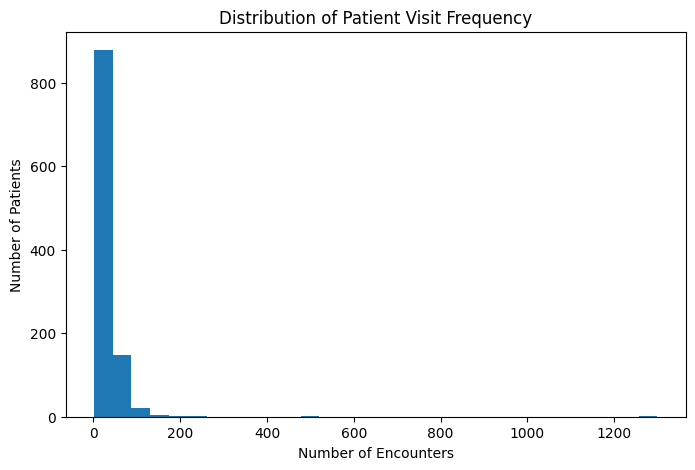

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(patient_features['FREQUENCY'], bins=30)

plt.title('Distribution of Patient Visit Frequency')
plt.xlabel('Number of Encounters')
plt.ylabel('Number of Patients')

plt.show()

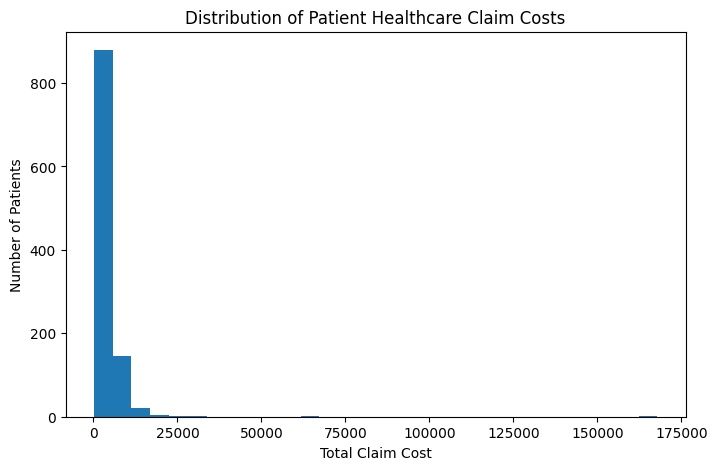

In [34]:
plt.figure(figsize=(8,5))

plt.hist(patient_features['MONETARY'].dropna(), bins=30)

plt.title('Distribution of Patient Healthcare Claim Costs')
plt.xlabel('Total Claim Cost')
plt.ylabel('Number of Patients')

plt.show()

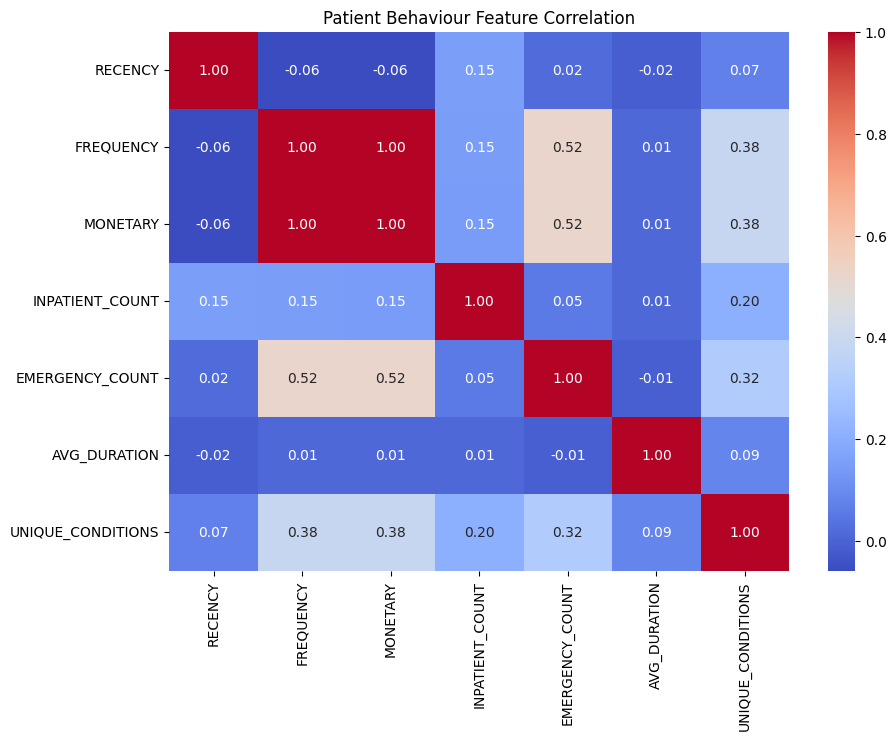

In [35]:
import seaborn as sns

numerical_features = [
    'RECENCY',
    'FREQUENCY',
    'MONETARY',
    'INPATIENT_COUNT',
    'EMERGENCY_COUNT',
    'AVG_DURATION',
    'UNIQUE_CONDITIONS'
]

correlation = patient_features[numerical_features].corr()

plt.figure(figsize=(10,7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Patient Behaviour Feature Correlation')

plt.show()

In [36]:
rfm = patient_features[
    ['PATIENT_ID', 'RECENCY', 'FREQUENCY', 'MONETARY']
].copy()

# Recency: lower days = better score
rfm['R_SCORE'] = pd.qcut(
    rfm['RECENCY'].rank(method='first'),
    5,
    labels=[5,4,3,2,1]
).astype(int)

# Frequency: higher visits = better score
rfm['F_SCORE'] = pd.qcut(
    rfm['FREQUENCY'].rank(method='first'),
    5,
    labels=[1,2,3,4,5]
).astype(int)

# Monetary: higher claim cost = higher score
rfm['M_SCORE'] = pd.qcut(
    rfm['MONETARY'].rank(method='first'),
    5,
    labels=[1,2,3,4,5]
).astype(int)

# Combined RFM score
rfm['RFM_SCORE'] = (
    rfm['R_SCORE'] +
    rfm['F_SCORE'] +
    rfm['M_SCORE']
)

display(rfm.head(10))

,PATIENT_ID,RECENCY,FREQUENCY,MONETARY,R_SCORE,F_SCORE,M_SCORE,RFM_SCORE
0,00185faa-2760-4218-9bf5-db301acf8274,13,22,2324.82,5,3,3,11
1,0042862c-9889-4a2e-b782-fac1e540ecb4,144,21,2712.36,3,3,3,9
2,0047123f-12e7-486c-82df-53b3a450e365,39,21,2660.69,4,3,3,10
3,010d4a3a-2316-45ed-ae15-16f01c611674,260,13,1679.08,2,1,1,4
4,01207ecd-9dff-4754-8887-4652eda231e2,5,6,774.96,5,1,1,7
5,0149d553-f571-4e99-867e-fcb9625d07c2,305,35,4520.60,1,4,4,9
6,01e1f394-7219-4189-bceb-3cbd90cff90b,276,40,5166.40,2,5,5,12
7,023a7d29-32b3-4db5-89c8-b88bd7582ec0,55,26,3358.16,4,4,4,12
8,0288abb6-633c-40c3-ba0c-66c7d957727e,173,31,4003.96,3,4,4,11
9,02ea2f1a-ddcf-4809-8279-dde7a62e0318,382,7,904.12,1,1,1,3


In [37]:
def assign_segment(row):

    if row['RFM_SCORE'] >= 12:
        return 'High Engagement'

    elif row['RFM_SCORE'] >= 9:
        return 'Regular Patients'

    elif row['RFM_SCORE'] >= 6:
        return 'Occasional Patients'

    else:
        return 'Low Engagement'

rfm['RFM_SEGMENT'] = rfm.apply(
    assign_segment,
    axis=1
)

print(rfm['RFM_SEGMENT'].value_counts())

RFM_SEGMENT
Regular Patients       295
Occasional Patients    292
High Engagement        278
Low Engagement         191
Name: count, dtype: int64


In [38]:
# Skewness analysis

features = [
    'RECENCY',
    'FREQUENCY',
    'MONETARY',
    'INPATIENT_COUNT',
    'EMERGENCY_COUNT',
    'AVG_DURATION',
    'UNIQUE_CONDITIONS'
]

print("FEATURE SKEWNESS")

display(
    patient_features[features].skew().sort_values(
        ascending=False
    )
)

FEATURE SKEWNESS


,0
EMERGENCY_COUNT,21.165176
MONETARY,18.737651
FREQUENCY,18.695006
AVG_DURATION,13.704833
INPATIENT_COUNT,7.477421
RECENCY,4.307515
UNIQUE_CONDITIONS,1.114084


In [39]:
for col in features:

    Q1 = patient_features[col].quantile(0.25)
    Q3 = patient_features[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = patient_features[
        (patient_features[col] < lower) |
        (patient_features[col] > upper)
    ]

    print(
        col,
        "- Outliers:",
        len(outliers)
    )

RECENCY - Outliers: 88
FREQUENCY - Outliers: 86
MONETARY - Outliers: 94
INPATIENT_COUNT - Outliers: 177
EMERGENCY_COUNT - Outliers: 19
AVG_DURATION - Outliers: 166
UNIQUE_CONDITIONS - Outliers: 21


In [40]:
print("RFM SEGMENT DISTRIBUTION")

display(
    rfm['RFM_SEGMENT'].value_counts().to_frame(
        name='PATIENT_COUNT'
    )
)

print("\nSegment percentages:")

display(
    (rfm['RFM_SEGMENT'].value_counts(normalize=True) * 100)
    .round(2)
)

RFM SEGMENT DISTRIBUTION


,PATIENT_COUNT
RFM_SEGMENT,
Regular Patients,295
Occasional Patients,292
High Engagement,278
Low Engagement,191



Segment percentages:


,proportion
RFM_SEGMENT,
Regular Patients,27.94
Occasional Patients,27.65
High Engagement,26.33
Low Engagement,18.09


In [41]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cluster_features = [
    'RECENCY',
    'FREQUENCY',
    'MONETARY',
    'INPATIENT_COUNT',
    'EMERGENCY_COUNT',
    'AVG_DURATION',
    'UNIQUE_CONDITIONS'
]

X = patient_features[cluster_features].copy()

print("Missing values:")
print(X.isnull().sum())

print("\nDataset shape:", X.shape)

Missing values:
RECENCY              0
FREQUENCY            0
MONETARY             0
INPATIENT_COUNT      0
EMERGENCY_COUNT      0
AVG_DURATION         0
UNIQUE_CONDITIONS    0
dtype: int64

Dataset shape: (1056, 7)


In [42]:
# Create a separate copy
X_processed = X.copy()

# Cap extreme values at 1st and 99th percentiles
for col in X_processed.columns:

    lower = X_processed[col].quantile(0.01)
    upper = X_processed[col].quantile(0.99)

    X_processed[col] = X_processed[col].clip(
        lower=lower,
        upper=upper
    )

# Apply log transformation
X_processed = np.log1p(X_processed)

print("Transformation completed!")

display(X_processed.describe())

Transformation completed!


,RECENCY,FREQUENCY,MONETARY,INPATIENT_COUNT,EMERGENCY_COUNT,AVG_DURATION,UNIQUE_CONDITIONS
count,1056.000000,1056.000000,1056.000000,1056.000000,1056.000000,1056.000000,1056.000000
mean,4.698526,3.101913,7.904474,0.218667,0.645942,0.115171,1.786154
std,1.369564,0.658170,0.691194,0.618266,0.561874,0.323142,0.541531
min,1.098612,1.609438,6.249280,0.000000,0.000000,0.011376,0.000000
25%,3.871201,2.708050,7.500662,0.000000,0.000000,0.015580,1.386294
50%,4.875197,2.995732,7.805898,0.000000,0.693147,0.019600,1.791759
75%,5.614039,3.496508,8.303224,0.000000,1.098612,0.039785,2.197225
max,7.759742,4.820282,9.673299,3.479700,2.008214,2.214439,2.890372


In [43]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_processed)

print("Standardisation completed!")
print("Scaled dataset shape:", X_scaled.shape)

Standardisation completed!
Scaled dataset shape: (1056, 7)


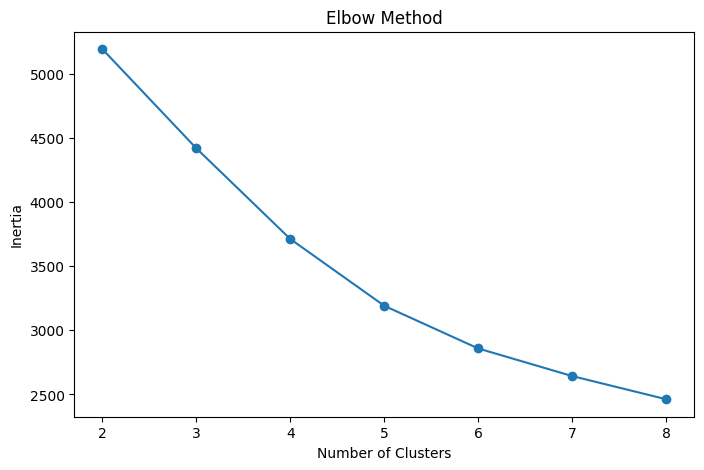

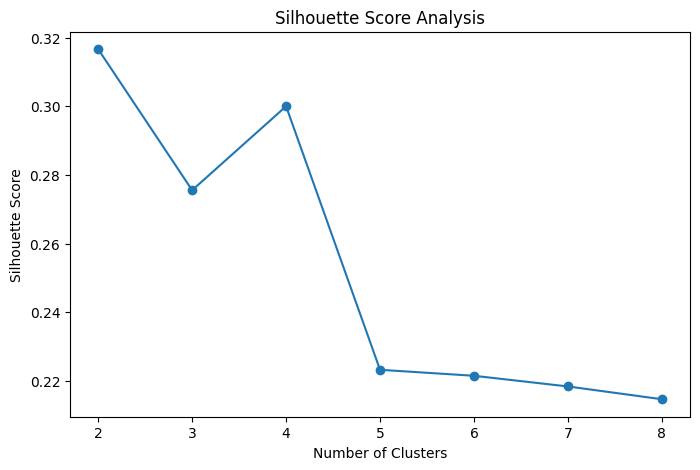

Silhouette scores:
K=2: 0.3166
K=3: 0.2756
K=4: 0.3000
K=5: 0.2233
K=6: 0.2215
K=7: 0.2184
K=8: 0.2147


In [44]:
inertia = []
silhouette_scores = []

K = range(2, 9)

for k in K:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertia.append(model.inertia_)

    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

# Elbow graph
plt.figure(figsize=(8, 5))

plt.plot(K, inertia, marker='o')

plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')

plt.show()

# Silhouette graph
plt.figure(figsize=(8, 5))

plt.plot(K, silhouette_scores, marker='o')

plt.title('Silhouette Score Analysis')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')

plt.show()

print("Silhouette scores:")

for k, score in zip(K, silhouette_scores):
    print(f"K={k}: {score:.4f}")

In [45]:
# Display all DataFrames currently available

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(f"{name}: {obj.shape}")

patients: (1171, 25)
encounters: (53346, 17)
df: (8376, 6)
summary: (16, 4)
conditions: (8376, 6)
organizations: (1119, 11)
org_counts: (1103, 2)
org_analysis: (1103, 6)
yearly_summary: (108, 3)
enc: (30520, 17)
pat: (1171, 26)
cond: (8376, 6)
patient_features: (1056, 11)
condition_features: (1152, 2)
demographics: (1171, 3)
correlation: (7, 7)
rfm: (1056, 9)
outliers: (21, 11)
X: (1056, 7)
X_processed: (1056, 7)


In [46]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

# Store clustering results
kmeans_results = {}

for k in [2, 4]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_processed)

    score = silhouette_score(X_processed, labels)

    kmeans_results[k] = {
        'model': model,
        'labels': labels,
        'silhouette': score
    }

    print(f"\nK = {k}")
    print("Silhouette Score:", round(score, 4))

    print("\nPatient Distribution:")
    print(pd.Series(labels).value_counts().sort_index())



K = 2
Silhouette Score: 0.3365

Patient Distribution:
0    366
1    690
Name: count, dtype: int64

K = 4
Silhouette Score: 0.2322

Patient Distribution:
0    235
1    170
2    282
3    369
Name: count, dtype: int64


In [48]:
# Create patient profiles for both K-Means models

features = [
    'RECENCY',
    'FREQUENCY',
    'MONETARY',
    'INPATIENT_COUNT',
    'EMERGENCY_COUNT',
    'AVG_DURATION',
    'TOTAL_DURATION',
    'UNIQUE_CONDITIONS',
    'AGE'
]

for k in [2, 4]:

    profile_data = patient_features.copy()

    profile_data['CLUSTER'] = kmeans_results[k]['labels']

    print(f"\n{'='*50}")
    print(f"K-MEANS SEGMENT PROFILE: K={k}")
    print('='*50)

    # Calculate average behaviour of each cluster
    profile = profile_data.groupby('CLUSTER')[features].mean()

    # Calculate cluster size
    profile['PATIENT_COUNT'] = (
        profile_data.groupby('CLUSTER').size()
    )

    # Calculate percentage
    profile['PERCENTAGE'] = (
        profile['PATIENT_COUNT'] /
        len(profile_data) * 100
    )

    display(profile.round(2))


K-MEANS SEGMENT PROFILE: K=2


,RECENCY,FREQUENCY,MONETARY,INPATIENT_COUNT,EMERGENCY_COUNT,AVG_DURATION,TOTAL_DURATION,UNIQUE_CONDITIONS,AGE,PATIENT_COUNT,PERCENTAGE
CLUSTER,,,,,,,,,,,
0,36.70,44.26,5693.69,1.93,1.81,0.71,29.24,6.94,41.27,366,34.66
1,365.19,20.76,2678.70,0.63,1.10,0.38,9.56,5.25,40.55,690,65.34



K-MEANS SEGMENT PROFILE: K=4


,RECENCY,FREQUENCY,MONETARY,INPATIENT_COUNT,EMERGENCY_COUNT,AVG_DURATION,TOTAL_DURATION,UNIQUE_CONDITIONS,AGE,PATIENT_COUNT,PERCENTAGE
CLUSTER,,,,,,,,,,,
0,268.02,48.14,6188.57,3.02,2.75,0.98,46.17,7.94,43.08,235,22.25
1,15.28,54.70,7051.68,2.10,2.09,0.91,24.36,7.91,44.39,170,16.10
2,73.26,16.37,2112.82,0.04,0.52,0.15,2.51,4.27,36.64,282,26.70
3,485.56,14.34,1851.71,0.17,0.73,0.26,4.34,4.73,40.87,369,34.94


In [49]:
# Compare RFM and K-Means patient distributions

print("RFM SEGMENT DISTRIBUTION")
print(rfm['RFM_SEGMENT'].value_counts())

print("\nRFM SEGMENT PERCENTAGES")
print(
    rfm['RFM_SEGMENT']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

for k in [2, 4]:

    print(f"\nK-MEANS DISTRIBUTION (K={k})")

    labels = kmeans_results[k]['labels']

    distribution = pd.Series(labels).value_counts().sort_index()

    print(distribution)

    print("\nPercentage Distribution:")

    print(
        (distribution / len(labels) * 100).round(2)
    )

RFM SEGMENT DISTRIBUTION
RFM_SEGMENT
Regular Patients       295
Occasional Patients    292
High Engagement        278
Low Engagement         191
Name: count, dtype: int64

RFM SEGMENT PERCENTAGES
RFM_SEGMENT
Regular Patients       27.94
Occasional Patients    27.65
High Engagement        26.33
Low Engagement         18.09
Name: proportion, dtype: float64

K-MEANS DISTRIBUTION (K=2)
0    366
1    690
Name: count, dtype: int64

Percentage Distribution:
0    34.66
1    65.34
Name: count, dtype: float64

K-MEANS DISTRIBUTION (K=4)
0    235
1    170
2    282
3    369
Name: count, dtype: int64

Percentage Distribution:
0    22.25
1    16.10
2    26.70
3    34.94
Name: count, dtype: float64


In [50]:
for k in [2, 4]:

    labels = kmeans_results[k]['labels']

    percentages = (
        pd.Series(labels)
        .value_counts(normalize=True) * 100
    )

    print(f"\nK={k}")

    print(percentages.round(2))

    if (percentages >= 5).all():
        print("All clusters satisfy the 5% requirement")
    else:
        print("Some clusters are below the 5% requirement")


K=2
1    65.34
0    34.66
Name: proportion, dtype: float64
All clusters satisfy the 5% requirement

K=4
3    34.94
2    26.70
0    22.25
1    16.10
Name: proportion, dtype: float64
All clusters satisfy the 5% requirement


In [51]:
# Compare model performance

for k in [2, 4]:

    print(f"\nK = {k}")

    print(
        "Silhouette Score:",
        round(kmeans_results[k]['silhouette'], 4)
    )


K = 2
Silhouette Score: 0.3365

K = 4
Silhouette Score: 0.2322


In [52]:
# Detailed K=4 cluster profiles

profile_data = patient_features.copy()

profile_data['CLUSTER'] = kmeans_results[4]['labels']

cluster_profile = profile_data.groupby('CLUSTER').agg(
    PATIENT_COUNT=('PATIENT_ID', 'count'),
    AVG_RECENCY=('RECENCY', 'mean'),
    AVG_FREQUENCY=('FREQUENCY', 'mean'),
    AVG_SPENDING=('MONETARY', 'mean'),
    AVG_INPATIENT=('INPATIENT_COUNT', 'mean'),
    AVG_EMERGENCY=('EMERGENCY_COUNT', 'mean'),
    AVG_STAY=('AVG_DURATION', 'mean'),
    AVG_CONDITIONS=('UNIQUE_CONDITIONS', 'mean')
)

cluster_profile['PATIENT_PERCENTAGE'] = (
    cluster_profile['PATIENT_COUNT'] /
    len(profile_data) * 100
)

display(cluster_profile.round(2))

,PATIENT_COUNT,AVG_RECENCY,AVG_FREQUENCY,AVG_SPENDING,AVG_INPATIENT,AVG_EMERGENCY,AVG_STAY,AVG_CONDITIONS,PATIENT_PERCENTAGE
CLUSTER,,,,,,,,,
0,235,268.02,48.14,6188.57,3.02,2.75,0.98,7.94,22.25
1,170,15.28,54.70,7051.68,2.10,2.09,0.91,7.91,16.10
2,282,73.26,16.37,2112.82,0.04,0.52,0.15,4.27,26.70
3,369,485.56,14.34,1851.71,0.17,0.73,0.26,4.73,34.94


In [53]:
# K=2 patient cluster profiling

profile_data = patient_features.copy()

profile_data['CLUSTER'] = kmeans_results[2]['labels']

k2_profile = profile_data.groupby('CLUSTER').agg(
    PATIENT_COUNT=('PATIENT_ID', 'count'),
    AVG_RECENCY=('RECENCY', 'mean'),
    AVG_FREQUENCY=('FREQUENCY', 'mean'),
    AVG_SPENDING=('MONETARY', 'mean'),
    AVG_INPATIENT=('INPATIENT_COUNT', 'mean'),
    AVG_EMERGENCY=('EMERGENCY_COUNT', 'mean'),
    AVG_STAY=('AVG_DURATION', 'mean'),
    AVG_CONDITIONS=('UNIQUE_CONDITIONS', 'mean')
)

k2_profile['PATIENT_PERCENTAGE'] = (
    k2_profile['PATIENT_COUNT'] /
    len(profile_data) * 100
)

display(k2_profile.round(2))

,PATIENT_COUNT,AVG_RECENCY,AVG_FREQUENCY,AVG_SPENDING,AVG_INPATIENT,AVG_EMERGENCY,AVG_STAY,AVG_CONDITIONS,PATIENT_PERCENTAGE
CLUSTER,,,,,,,,,
0,366,36.70,44.26,5693.69,1.93,1.81,0.71,6.94,34.66
1,690,365.19,20.76,2678.70,0.63,1.10,0.38,5.25,65.34


In [54]:
# Final K-Means segmentation

final_data = patient_features.copy()

final_data['CLUSTER'] = kmeans_results[4]['labels']

# Assign business-friendly names
segment_names = {
    0: 'High-Value Inactive',
    1: 'High-Value Active',
    2: 'Moderate Utilisation',
    3: 'Low Engagement'
}

final_data['SEGMENT'] = final_data['CLUSTER'].map(segment_names)

# Calculate segment profiles
final_profile = final_data.groupby('SEGMENT').agg(
    PATIENT_COUNT=('PATIENT_ID', 'count'),
    AVG_RECENCY=('RECENCY', 'mean'),
    AVG_FREQUENCY=('FREQUENCY', 'mean'),
    TOTAL_CLAIM_COST=('MONETARY', 'sum'),
    AVG_CLAIM_COST=('MONETARY', 'mean'),
    AVG_INPATIENT=('INPATIENT_COUNT', 'mean'),
    AVG_EMERGENCY=('EMERGENCY_COUNT', 'mean'),
    AVG_DURATION=('AVG_DURATION', 'mean'),
    AVG_CONDITIONS=('UNIQUE_CONDITIONS', 'mean')
)

final_profile['PATIENT_PERCENTAGE'] = (
    final_profile['PATIENT_COUNT'] /
    len(final_data) * 100
)

final_profile['CLAIM_COST_SHARE'] = (
    final_profile['TOTAL_CLAIM_COST'] /
    final_profile['TOTAL_CLAIM_COST'].sum() * 100
)

display(final_profile.round(2))

,PATIENT_COUNT,AVG_RECENCY,AVG_FREQUENCY,TOTAL_CLAIM_COST,AVG_CLAIM_COST,AVG_INPATIENT,AVG_EMERGENCY,AVG_DURATION,AVG_CONDITIONS,PATIENT_PERCENTAGE,CLAIM_COST_SHARE
SEGMENT,,,,,,,,,,,
High-Value Active,170,15.28,54.70,1198785.36,7051.68,2.10,2.09,0.91,7.91,16.10,30.49
High-Value Inactive,235,268.02,48.14,1454314.97,6188.57,3.02,2.75,0.98,7.94,22.25,36.98
Low Engagement,369,485.56,14.34,683282.19,1851.71,0.17,0.73,0.26,4.73,34.94,17.38
Moderate Utilisation,282,73.26,16.37,595815.05,2112.82,0.04,0.52,0.15,4.27,26.70,15.15


In [55]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Scale the processed features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_processed)

# Compare different cluster counts
for k in range(2, 7):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    print(f"K = {k}")
    print(f"Silhouette Score: {score:.4f}")
    print("Cluster Distribution:")
    print(pd.Series(labels).value_counts(normalize=True).sort_index().round(3))
    print("-" * 40)

K = 2
Silhouette Score: 0.3166
Cluster Distribution:
0    0.65
1    0.35
Name: proportion, dtype: float64
----------------------------------------
K = 3
Silhouette Score: 0.2756
Cluster Distribution:
0    0.562
1    0.360
2    0.079
Name: proportion, dtype: float64
----------------------------------------
K = 4
Silhouette Score: 0.3000
Cluster Distribution:
0    0.360
1    0.549
2    0.050
3    0.041
Name: proportion, dtype: float64
----------------------------------------
K = 5
Silhouette Score: 0.2233
Cluster Distribution:
0    0.455
1    0.045
2    0.041
3    0.222
4    0.238
Name: proportion, dtype: float64
----------------------------------------
K = 6
Silhouette Score: 0.2215
Cluster Distribution:
0    0.205
1    0.219
2    0.045
3    0.162
4    0.041
5    0.329
Name: proportion, dtype: float64
----------------------------------------


In [56]:
# Train final K=3 model
final_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

final_labels = final_model.fit_predict(X_scaled)

# Attach cluster labels to patient data
final_data = patient_features.copy()
final_data['CLUSTER'] = final_labels

# Generate cluster profiles
final_profile = final_data.groupby('CLUSTER').agg(
    PATIENT_COUNT=('CLUSTER', 'count'),
    AVG_RECENCY=('RECENCY', 'mean'),
    AVG_FREQUENCY=('FREQUENCY', 'mean'),
    TOTAL_CLAIM_COST=('MONETARY', 'sum'),
    AVG_CLAIM_COST=('MONETARY', 'mean'),
    AVG_INPATIENT=('INPATIENT_COUNT', 'mean'),
    AVG_EMERGENCY=('EMERGENCY_COUNT', 'mean'),
    AVG_DURATION=('AVG_DURATION', 'mean'),
    AVG_CONDITIONS=('UNIQUE_CONDITIONS', 'mean')
)

# Calculate percentages
final_profile['PATIENT_PERCENTAGE'] = (
    final_profile['PATIENT_COUNT'] /
    len(final_data) * 100
)

final_profile['CLAIM_COST_SHARE'] = (
    final_profile['TOTAL_CLAIM_COST'] /
    final_profile['TOTAL_CLAIM_COST'].sum() * 100
)

display(final_profile.round(2))

,PATIENT_COUNT,AVG_RECENCY,AVG_FREQUENCY,TOTAL_CLAIM_COST,AVG_CLAIM_COST,AVG_INPATIENT,AVG_EMERGENCY,AVG_DURATION,AVG_CONDITIONS,PATIENT_PERCENTAGE,CLAIM_COST_SHARE
CLUSTER,,,,,,,,,,,
0,593,305.26,14.23,1089567.88,1837.38,0.07,0.53,0.09,4.18,56.16,27.71
1,380,140.86,44.86,2200912.16,5791.87,0.24,2.20,0.08,7.66,35.98,55.97
2,83,371.84,60.67,641717.53,7731.54,12.18,3.28,5.26,9.30,7.86,16.32


In [57]:
# Check encounter class distribution in each cluster

check_data = patient_features[['INPATIENT_COUNT',
                               'EMERGENCY_COUNT']].copy()

check_data['CLUSTER'] = final_labels

print("Cluster-wise inpatient and emergency statistics:")

display(
    check_data.groupby('CLUSTER')[
        ['INPATIENT_COUNT', 'EMERGENCY_COUNT']
    ].describe().round(2)
)

Cluster-wise inpatient and emergency statistics:


INPATIENT_COUNT                                           \
                  count   mean    std  min  25%  50%   75%   max   
CLUSTER                                                            
0                 593.0   0.07   0.26  0.0  0.0  0.0   0.0   2.0   
1                 380.0   0.24   0.53  0.0  0.0  0.0   0.0   3.0   
2                  83.0  12.18  15.82  0.0  1.0  5.0  19.5  59.0   

        EMERGENCY_COUNT                                        
                  count  mean   std  min  25%  50%  75%   max  
CLUSTER                                                        
0                 593.0  0.53  0.66  0.0  0.0  0.0  1.0   4.0  
1                 380.0  2.20  1.69  0.0  1.0  2.0  3.0  15.0  
2                  83.0  3.28  9.29  0.0  1.0  2.0  3.0  85.0

In [58]:
# Inspect patients with the highest inpatient utilisation

cluster2 = final_data[final_data['CLUSTER'] == 2]

top_inpatient = cluster2.sort_values(
    by='INPATIENT_COUNT',
    ascending=False
)

display(
    top_inpatient[
        ['INPATIENT_COUNT',
         'EMERGENCY_COUNT',
         'FREQUENCY',
         'MONETARY',
         'RECENCY',
         'AVG_DURATION']
    ].head(10)
)

,INPATIENT_COUNT,EMERGENCY_COUNT,FREQUENCY,MONETARY,RECENCY,AVG_DURATION
602,59,2,78,10074.48,581,0.843429
872,59,2,84,10849.44,1579,0.780150
840,58,2,120,15499.20,93,0.497367
440,52,0,96,12399.36,4,1.338028
754,52,1,85,10978.60,22,1.497443
427,46,0,59,7620.44,2715,0.809216
360,40,0,50,6458.00,2542,0.855417
82,40,1,65,8395.40,58,0.632596
372,37,0,58,5579.49,105,0.644385
219,36,2,50,6458.00,1525,0.805472


In [60]:
# Check whether inpatient and emergency counts
# exceed the total encounter frequency

print("Inpatient count > frequency:",
      (final_data['INPATIENT_COUNT'] >
       final_data['FREQUENCY']).sum())

print("Emergency count > frequency:",
      (final_data['EMERGENCY_COUNT'] >
       final_data['FREQUENCY']).sum())

print("Missing values in final features:")
print(final_data.isnull().sum())

Inpatient count > frequency: 0
Emergency count > frequency: 0
Missing values in final features:
PATIENT_ID           0
RECENCY              0
FREQUENCY            0
MONETARY             0
INPATIENT_COUNT      0
EMERGENCY_COUNT      0
AVG_DURATION         0
TOTAL_DURATION       0
UNIQUE_CONDITIONS    0
GENDER               0
AGE                  0
CLUSTER              0
dtype: int64
